# ICT-4202 | Artificial Intelligence and Machine Learning Laboratory
## Final Laboratory Examination — Set 04
**Islamic University, Kushtia, Bangladesh**  
Department of Information and Communication Technology

> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | BFS/DFS/bidirectional search | 30 |
| Q2 | WEKA J48 and IBk cross-validation | 30 |
| Q3 | Linear regression and perturbation | 30 |
| Q4 | Viva: search, WEKA CV, IBk, regression | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_04_A.py) | [Q2 / B](Set_04_B.py) | [Q3 / C](Set_04_C.py) | [Q4 / D: Viva practice](Set_04_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. Search Comparison (30 marks)
**Question specification**  
`P→{Q,R}, Q→{S,T}, R→{U}, S→{V}, T→{V}, U→{V}, V→{}`. Compare BFS, DFS, bidirectional search from P to V, showing path, expansion order, number expanded. Reverse the neighbor order of Q and rerun DFS.

### Theory and mathematical background
For an unweighted graph, **BFS** expands the shallowest frontier state first (FIFO queue), so it finds a minimum-edge path when each edge has equal cost. **DFS** explores a branch deeply first (LIFO stack), so its outcome depends on neighbor order. A **visited set** prevents re-expansion.

With $V$ vertices and $E$ edges, BFS and DFS can both run in $O(V+E)$ time on an adjacency-list graph; their frontier sizes and discovered-node storage differ. In tree-search notation, BFS typically uses $O(b^{d+1})$ space, while DFS uses $O(bm)$ space ($b$ branching factor, $d$ shallowest goal depth, $m$ maximum depth). These are different models of complexity.

**Bidirectional search** grows frontiers from both ends. For a directed graph, the backward frontier must use **reversed edges**, otherwise it may report an invalid path.

In [1]:
from collections import deque

import heapq

from itertools import count

def bfs(graph, start, goal):
    queue = deque([(start, [start])])
    seen = {start}
    expanded = []
    while queue:
        node, path = queue.popleft()
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, path + [nxt]))
    return None, expanded

def dfs(graph, start, goal):
    stack = [(start, [start])]
    seen = set()
    expanded = []
    while stack:
        node, path = stack.pop()
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        # Reverse push order so the FIRST listed neighbor is explored first.
        for nxt in reversed(graph.get(node, [])):
            if nxt not in seen:
                stack.append((nxt, path + [nxt]))
    return None, expanded

from collections import deque

def bidirectional_search(graph, start, goal):
    """BFS forward on directed edges and backward on their reversed edges."""
    if start == goal: return [start], [('forward', start)]
    reverse = {u: [] for u in graph}
    for u, neighbors in graph.items():
        for v in neighbors:
            reverse.setdefault(v, []).append(u)
    f_queue, b_queue = deque([start]), deque([goal])
    forward_paths, backward_paths = {start:[start]}, {goal:[goal]}
    trace = []
    while f_queue and b_queue:
        for direction, queue, own, other, adjacency in [
            ('forward', f_queue, forward_paths, backward_paths, graph),
            ('backward', b_queue, backward_paths, forward_paths, reverse),
        ]:
            for _ in range(len(queue)):
                node = queue.popleft()
                trace.append((direction, node))
                if node in other:
                    return forward_paths[node] + backward_paths[node][1:], trace
                for nxt in adjacency.get(node, []):
                    if nxt in own: continue
                    own[nxt] = (own[node] + [nxt]) if direction == 'forward' else ([nxt] + own[node])
                    queue.append(nxt)
                    if nxt in other:
                        return forward_paths[nxt] + backward_paths[nxt][1:], trace
    return None, trace

graph={'P':['Q','R'],'Q':['S','T'],'R':['U'],'S':['V'],
       'T':['V'],'U':['V'],'V':[]}
for label, fn in [('BFS',bfs),('DFS',dfs)]:
    path, expanded = fn(graph,'P','V')
    print(f'{label}: path={path}; expanded={expanded}; expanded count={len(expanded)}')
bidir_path,bidir_trace=bidirectional_search(graph,'P','V')
print('Bidirectional:',bidir_path,'| expansion order (direction, node):',bidir_trace,
      '| expanded count:',len(bidir_trace))
changed={k:list(v) for k,v in graph.items()}
changed['Q']=list(reversed(changed['Q']))
print('DFS with Q children reversed:',dfs(changed,'P','V'))


BFS: path=['P', 'Q', 'S', 'V']; expanded=['P', 'Q', 'R', 'S', 'T', 'U', 'V']; expanded count=7
DFS: path=['P', 'Q', 'S', 'V']; expanded=['P', 'Q', 'S', 'V']; expanded count=4
Bidirectional: ['P', 'Q', 'S', 'V'] | expansion order (direction, node): [('forward', 'P'), ('backward', 'V'), ('forward', 'Q')] | expanded count: 3
DFS with Q children reversed: (['P', 'Q', 'T', 'V'], ['P', 'Q', 'T', 'V'])


### Result interpretation and discussion
Reversing Q’s adjacency from `[S,T]` to `[T,S]` changes **DFS branch ordering**; depending on how quickly the goal is found, the route or trace can change. Bidirectional expansions are counted as actual **dequeued** nodes in both directions; a meeting discovered during successor generation may not itself be dequeued.

---
## Q2. WEKA Classification (30 marks)
**Question specification**  
Using `iris.arff` in WEKA Explorer, inspect attributes and set the correct class. Run **J48** with 10-fold CV and **IBk** at $k=1,3,5$; record accuracy/confusion matrices, compare J48 to best IBk; save screenshots/result buffers.

### Theory and mathematical background
**WEKA Explorer** is a GUI workbench for data mining. In this experiment:
- `J48` is a C4.5-style decision-tree implementation.
- `IBk` is a nearest-neighbor classifier; the value of $k$ controls the number of neighbors.
- In **10-fold cross-validation**, the dataset is partitioned into ten folds. Each fold is evaluated once using a model trained on the remaining folds. A common summary is:
$$\mathrm{CV\ accuracy}=\frac{\text{total held-out correct predictions}}{\text{total held-out predictions}}.$$

A saved **WEKA result buffer** is required evidence: a Python evaluation of a similar method must not be presented as if it were the output of WEKA. To prevent preprocessing leakage, use WEKA's **FilteredClassifier** when evaluating scaling under cross-validation.

In [2]:
from pathlib import Path
from scipy.io import arff
from collections import Counter
# Use the same data file in a notebook and in a standalone Python script.
try:
    iris_path = Path(__file__).with_name("iris.arff")
except NameError:  # Jupyter notebooks do not define __file__.
    iris_path = Path("iris.arff")
data,meta=arff.loadarff(iris_path)
classes=[s.decode('utf-8') for s in data['class']]
print('File:',iris_path.resolve())
print('WEKA attributes:',meta.names())
print('Instances:',len(data),'| class counts:',dict(Counter(classes)))
assert len(data)==150 and len(set(classes))==3
print("NOTE: These are dataset checks only; run J48/IBk in WEKA Explorer and record its real results.")


File: /Users/macbookair/Desktop/Disk Sajjad/IU ICT 2020-21/Academic Files/4th Year 2nd Semester/ICT-4202 Artificial Intelligence and Machine Learning Laboratory/ICT-4202-AI-ML-Laboratory/Set_04/iris.arff
WEKA attributes: ['sepallength', 'sepalwidth', 'petallength', 'petalwidth', 'class']
Instances: 150 | class counts: {'Iris-setosa': 50, 'Iris-versicolor': 50, 'Iris-virginica': 50}
NOTE: These are dataset checks only; run J48/IBk in WEKA Explorer and record its real results.


### WEKA procedure (must be completed in WEKA)
1. Open **WEKA → Explorer → Preprocess → Open file → `iris.arff`** (provided in this set folder). Verify 150 instances and five attributes. Select `class` (the final, nominal attribute).
2. **Classify → Choose → `trees.J48` → Test options: Cross-validation, 10 folds → Start.** In the result list, right-click the run to view/copy the output buffer. Save an image of the confusion matrix.
3. Repeat in **Classify → `lazy.IBk`**, setting `KNN=1`, `KNN=3`, then `KNN=5`; retain the same 10-fold evaluation setup.
4. Record **Correctly Classified Instances (%), confusion matrix**, and optionally weighted F1. Compare the *measured* best IBk score to J48.

**Real WEKA results — fill after running the GUI**

| Classifier | k | 10-fold CV accuracy (%) | Confusion matrix / saved result |
|:--|--:|--:|:--|
| J48 | — | *run WEKA* | *attach real result buffer* |
| IBk | 1 | *run WEKA* | *attach real result buffer* |
| IBk | 3 | *run WEKA* | *attach real result buffer* |
| IBk | 5 | *run WEKA* | *attach real result buffer* |

**Why these results are blank:** WEKA is a separate Java application. The Python cell above only verifies the dataset; no WEKA performance figures are invented.

---
## Q3. Linear Regression (30 marks)
**Question specification**  
`X=[2,4,6,8,10,12]`, `Y=[5,9,13,17,21,25]`: fit regression, slope/intercept, predict at X=15, $R^2$, plot. Modify one target and explain effect.

### Theory and mathematical background
Simple linear regression estimates a numerical response from a predictor:
$$\hat y_i=\beta_0+\beta_1x_i.$$
The least-squares estimator minimizes
$$SSE=\sum_{i=1}^{n}\bigl(y_i-(\beta_0+\beta_1x_i)\bigr)^2,$$
with $\hat\beta_1=\frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}$ and $\hat\beta_0=\bar y-\hat\beta_1\bar x$.

The coefficient of determination is
$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$
An in-sample $R^2$ measures fit to the data used; test $R^2$ estimates performance on unseen data. With small test sets, the latter can be unstable or negative.

Original: slope=2.0000; intercept=1.0000; prediction(15)=31.0000; R²=1.0000
Changed last y (25→30): slope=2.3571; intercept=-0.6667; R²=0.9703


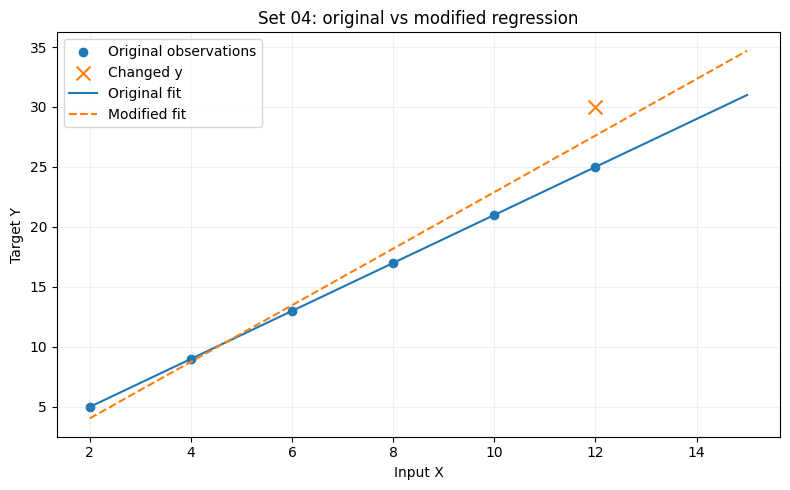

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
X=np.array([2,4,6,8,10,12],dtype=float).reshape(-1,1)
y=np.array([5,9,13,17,21,25],dtype=float)
fit=LinearRegression().fit(X,y)
print(f'Original: slope={fit.coef_[0]:.4f}; intercept={fit.intercept_:.4f}; '
      f'prediction(15)={fit.predict([[15]])[0]:.4f}; R²={fit.score(X,y):.4f}')
y_mod=y.copy(); y_mod[-1]=30  # Illustrative modification (question leaves value unspecified).
fit_mod=LinearRegression().fit(X,y_mod)
print(f'Changed last y (25→30): slope={fit_mod.coef_[0]:.4f}; '
      f'intercept={fit_mod.intercept_:.4f}; R²={fit_mod.score(X,y_mod):.4f}')
grid=np.linspace(2,15,80).reshape(-1,1)
plt.figure(figsize=(8,5))
plt.scatter(X[:,0],y,label='Original observations');plt.scatter([12],[30],marker='x',s=100,label='Changed y')
plt.plot(grid[:,0],fit.predict(grid),label='Original fit')
plt.plot(grid[:,0],fit_mod.predict(grid),'--',label='Modified fit')
plt.xlabel('Input X');plt.ylabel('Target Y');plt.title('Set 04: original vs modified regression')
plt.grid(alpha=.2);plt.legend();plt.tight_layout();plt.show()


### Result interpretation and discussion
The original points follow the **exact** relation $y=2x+1$, so in-sample $R^2=1$. Changing the last target to 30 is an *explicit illustrative choice*; the refitted line and $R^2$ change because the new data are no longer perfectly collinear.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| BFS versus DFS? | BFS expands breadth first (minimum-edge path); DFS follows a deep branch first. |
| How to run backward search on directed edges? | Use the reverse adjacency graph. |
| What is 10-fold CV? | Ten held-out validations, each using nine folds for training. |
| What is J48? | WEKA decision tree learner based on C4.5. |
| What is IBk? | WEKA nearest-neighbor classifier. |
| What does a regression slope mean? | Predicted response change for one unit of input. |

| What is bidirectional search? | Search from both start and goal, looking for a meeting point between the two frontiers. |
| Why report expanded nodes? | Expanded-node counts let us compare the effort used by different search strategies. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.